# EDA StereoQueerEval Training (semua bahasa)

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from tqdm.auto import tqdm
from transformers import AutoTokenizer

sns.set_theme(style="whitegrid", palette="Set2")

file_path = Path("StereoQueerEval_Training.xlsx")
if not file_path.exists():
    file_path = Path("Analisis") / "StereoQueerEval_Training.xlsx"

xls = pd.ExcelFile(file_path)
sheet_summary = pd.DataFrame([
    {"sheet": sheet, "rows": len(pd.read_excel(file_path, sheet_name=sheet)),
     "columns": len(pd.read_excel(file_path, sheet_name=sheet).columns)}
    for sheet in xls.sheet_names
])
print(f"File: {file_path.resolve()}")
print(f"Sheet tersedia: {xls.sheet_names}")
sheet_summary

File: E:\Projek\PTM\TBP\Analisis\StereoQueerEval_Training.xlsx
Sheet tersedia: ['EN', 'IT', 'NL', 'ALL_DATA']


,sheet,rows,columns
0,EN,2989,7
1,IT,2400,7
2,NL,2238,7
3,ALL_DATA,7627,8


## 1. Data seluruh bahasa dan struktur kolom

In [2]:
df = pd.read_excel(file_path, sheet_name="ALL_DATA")
label_cols = ["stereotype", "hate_speech", "target"]
languages = sorted(df["language"].dropna().unique())

print(f"Ukuran seluruh data: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print("Bahasa:", languages)
display(df.head())
print("\nTipe data:")
display(df.dtypes.rename("dtype").to_frame())

Ukuran seluruh data: 7,627 baris x 8 kolom
Bahasa: ['EN', 'IT', 'NL']


,StereoQueerEval_id,language,yt_title,yt_description,yt_comment,stereotype,hate_speech,target
0,training_EN_0001,EN,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes,yes_explicit,individual_l
1,training_EN_0002,EN,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes,yes_implicit,group_t
2,training_EN_0003,EN,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes,yes_implicit,"group_l,g"
3,training_EN_0004,EN,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes,yes_implicit,group_l
4,training_EN_0005,EN,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes,yes_implicit,group_g



Tipe data:


,dtype
StereoQueerEval_id,object
language,object
yt_title,object
yt_description,object
yt_comment,object
stereotype,object
hate_speech,object
target,object


## 2. Kualitas data dan duplikasi

In [3]:
blank_text = pd.Series({
    col: df[col].fillna("").astype(str).str.strip().eq("").sum()
    for col in ["yt_title", "yt_description", "yt_comment"]
})
quality = pd.DataFrame({
    "missing_cells": df.isna().sum(),
    "blank_text_cells": blank_text.reindex(df.columns, fill_value=0),
})
display(quality)
print("ID duplikat:", df["StereoQueerEval_id"].duplicated().sum())
print("Komentar duplikat:", df["yt_comment"].duplicated().sum())
print("Baris duplikat penuh:", df.duplicated().sum())

,missing_cells,blank_text_cells
StereoQueerEval_id,0,0
language,0,0
yt_title,0,0
yt_description,0,0
yt_comment,0,0
stereotype,0,0
hate_speech,0,0
target,0,0


ID duplikat: 0
Komentar duplikat: 1
Baris duplikat penuh: 0


## 3. Distribusi label utama

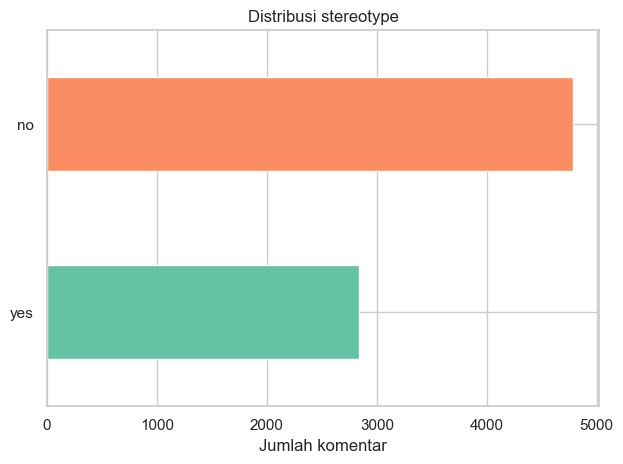

In [4]:
counts = df["stereotype"].fillna("(missing)").value_counts().sort_values()
counts.plot(kind="barh", color=sns.color_palette("Set2", len(counts)))
plt.title("Distribusi stereotype")
plt.xlabel("Jumlah komentar")
plt.ylabel("")
plt.tight_layout()

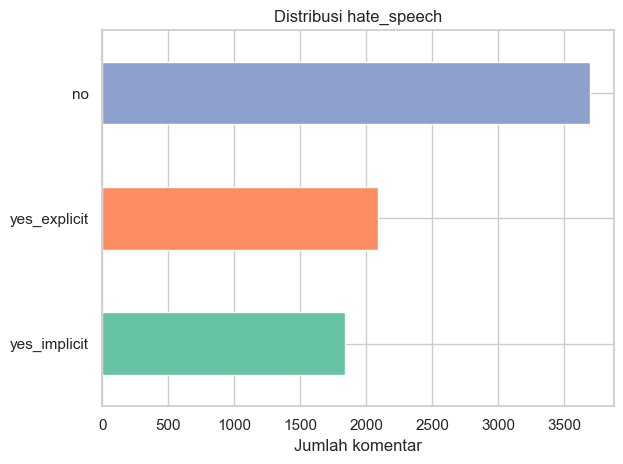

In [5]:
counts = df["hate_speech"].fillna("(missing)").value_counts().sort_values()
counts.plot(kind="barh", color=sns.color_palette("Set2", len(counts)))
plt.title("Distribusi hate_speech")
plt.xlabel("Jumlah komentar")
plt.ylabel("")
plt.tight_layout()

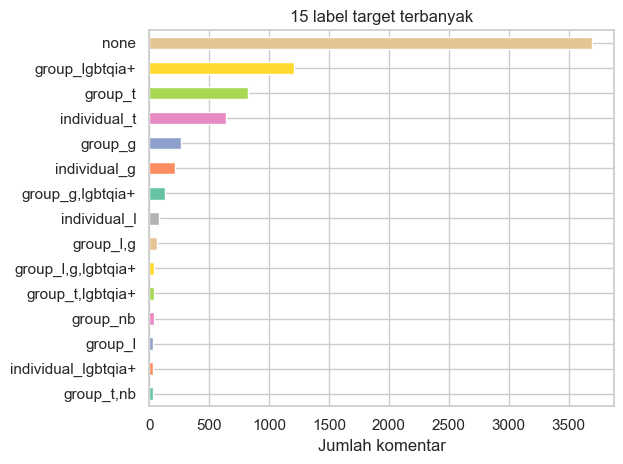

In [6]:
counts = df["target"].fillna("(missing)").value_counts().head(15).sort_values()
counts.plot(kind="barh", color=sns.color_palette("Set2", len(counts)))
plt.title("15 label target terbanyak")
plt.xlabel("Jumlah komentar")
plt.ylabel("")
plt.tight_layout()

In [7]:
for col in label_cols:
    print(f"\n{col}")
    display(pd.DataFrame({
        "count": df[col].value_counts(dropna=False),
        "percent": (df[col].value_counts(dropna=False, normalize=True) * 100).round(1)
    }))


stereotype


,count,percent
stereotype,,
no,4785,62.7
yes,2842,37.3



hate_speech


,count,percent
hate_speech,,
no,3694,48.4
yes_explicit,2093,27.4
yes_implicit,1840,24.1



target


,count,percent
target,,
none,3694,48.4
group_lgbtqia+,1211,15.9
group_t,823,10.8
individual_t,642,8.4
group_g,263,3.4
...,...,...
"individual_t,nb,lgbtqia+",1,0.0
"individual_g,q",1,0.0
"individual_nb,lgbtqia+",1,0.0


## 4. Perbandingan antarbahasa

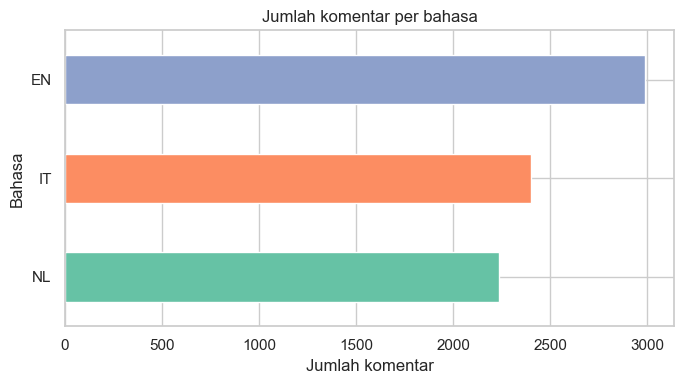

In [8]:
language_counts = df["language"].value_counts().sort_values()
language_counts.plot(kind="barh", figsize=(7, 4), color=sns.color_palette("Set2", len(language_counts)))
plt.title("Jumlah komentar per bahasa")
plt.xlabel("Jumlah komentar")
plt.ylabel("Bahasa")
plt.tight_layout()

stereotype,no,yes
language,,
EN,55.6,44.4
IT,73.0,27.0
NL,61.2,38.8


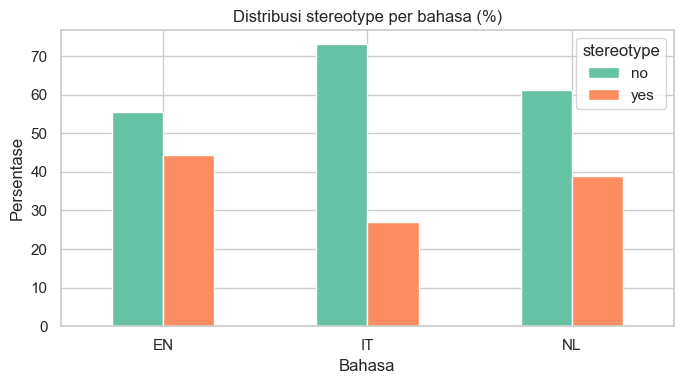

In [9]:
stereotype_by_language = pd.crosstab(df["language"], df["stereotype"], normalize="index").mul(100).round(1)
display(stereotype_by_language)
stereotype_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2", len(stereotype_by_language.columns)))
plt.title("Distribusi stereotype per bahasa (%)")
plt.xlabel("Bahasa")
plt.ylabel("Persentase")
plt.xticks(rotation=0)
plt.tight_layout()

hate_speech,no,yes_explicit,yes_implicit
language,,,
EN,47.1,27.1,25.8
IT,48.3,27.5,24.2
NL,50.4,27.9,21.8


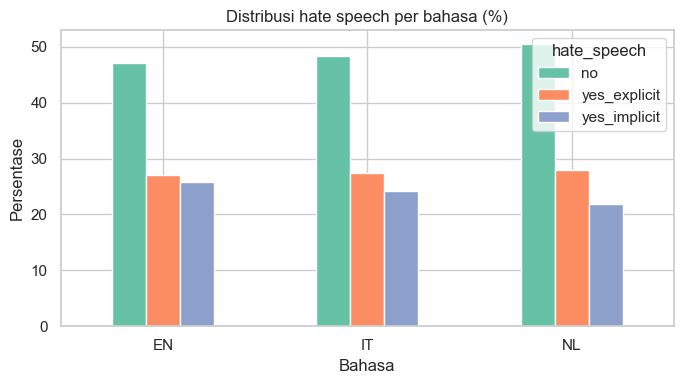

In [10]:
hate_by_language = pd.crosstab(df["language"], df["hate_speech"], normalize="index").mul(100).round(1)
display(hate_by_language)
hate_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2", len(hate_by_language.columns)))
plt.title("Distribusi hate speech per bahasa (%)")
plt.xlabel("Bahasa")
plt.ylabel("Persentase")
plt.xticks(rotation=0)
plt.tight_layout()

## 5. Hubungan antar-label dan target

hate_speech,no,yes_explicit,yes_implicit
stereotype,,,
no,3203,625,957
yes,491,1468,883



Cek target none terhadap hate speech:


hate_speech,no,yes_explicit,yes_implicit,All
target,,,,
False,0,2093,1840,3933
True,3694,0,0,3694
All,3694,2093,1840,7627



Cakupan target selain none:


,count
target_scope,
group,2827
individual,1106


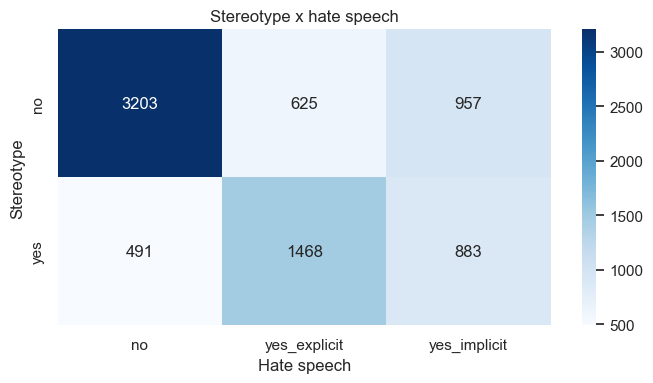

In [11]:
label_relation = pd.crosstab(df["stereotype"], df["hate_speech"])
plt.figure(figsize=(7, 4))
sns.heatmap(label_relation, annot=True, fmt="d", cmap="Blues")
plt.title("Stereotype x hate speech")
plt.xlabel("Hate speech")
plt.ylabel("Stereotype")
plt.tight_layout()
display(label_relation)

# Format target: group_<identity[,identity...]> atau individual_<identity[,identity...]>
target_parts = df["target"].fillna("").astype(str).str.split("_", n=1)
df["target_scope"] = target_parts.str[0]
df["target_identities"] = target_parts.str[1]
print("\nCek target none terhadap hate speech:")
display(pd.crosstab(df["target"].eq("none"), df["hate_speech"], margins=True))
print("\nCakupan target selain none:")
display(df.loc[df["target"] != "none", "target_scope"].value_counts().to_frame("count"))

target_scope,group,individual
language,,
EN,77.5,22.5
IT,69.6,30.4
NL,66.4,33.6


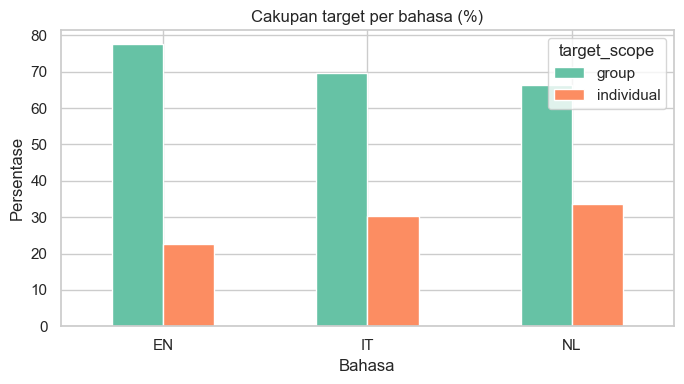

In [12]:
target_scope_by_language = pd.crosstab(
    df.loc[df["target"] != "none", "language"],
    df.loc[df["target"] != "none", "target_scope"],
    normalize="index"
).mul(100).round(1)
display(target_scope_by_language)
target_scope_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2", len(target_scope_by_language.columns)))
plt.title("Cakupan target per bahasa (%)")
plt.xlabel("Bahasa")
plt.ylabel("Persentase")
plt.xticks(rotation=0)
plt.tight_layout()

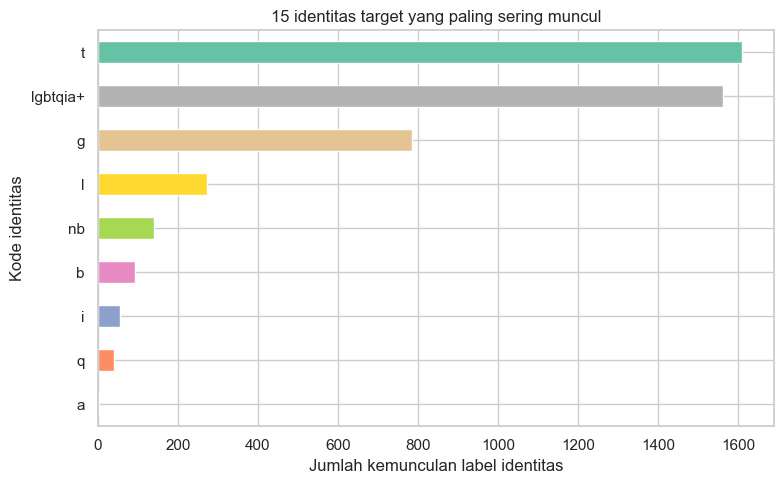

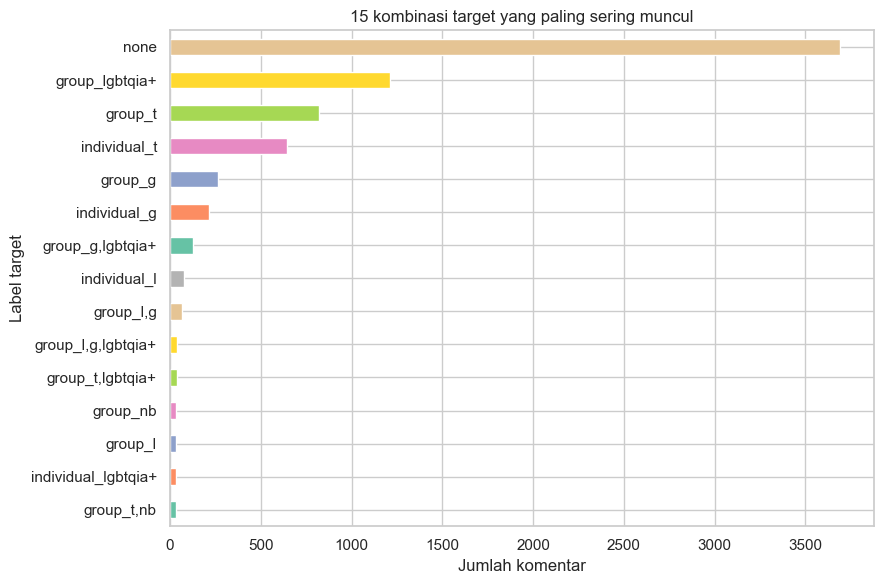

In [13]:
identity_counts = (
    df.loc[df["target"].notna() & df["target_identities"].notna(), "target_identities"]
      .str.split(",").explode().value_counts().head(15).sort_values()
)
plt.figure(figsize=(8, 5))
identity_counts.plot(kind="barh", color=sns.color_palette("Set2", len(identity_counts)))
plt.title("15 identitas target yang paling sering muncul")
plt.xlabel("Jumlah kemunculan label identitas")
plt.ylabel("Kode identitas")
plt.tight_layout()

combo_counts = df["target"].value_counts().head(15).sort_values()
plt.figure(figsize=(9, 6))
combo_counts.plot(kind="barh", color=sns.color_palette("Set2", len(combo_counts)))
plt.title("15 kombinasi target yang paling sering muncul")
plt.xlabel("Jumlah komentar")
plt.ylabel("Label target")
plt.tight_layout()

## 6. Panjang teks

In [14]:
text_cols = ["yt_title", "yt_description", "yt_comment"]
text_names = {"yt_title": "Judul", "yt_description": "Deskripsi", "yt_comment": "Komentar"}
for col in text_cols:
    text = df[col].fillna("").astype(str)
    df[f"{col}_chars"] = text.str.len()
    df[f"{col}_words"] = text.str.split().str.len()

length_summary = pd.DataFrame({
    text_names[col]: df[f"{col}_words"].describe(percentiles=[.5, .9, .95, .99])
    for col in text_cols
}).T.round(1)
display(length_summary)

,count,mean,std,min,50%,90%,95%,99%,max
Judul,7627.0,10.8,3.8,1.0,11.0,16.0,17.0,18.0,23.0
Deskripsi,7627.0,92.5,74.7,5.0,71.0,179.0,228.0,354.0,629.0
Komentar,7627.0,26.6,34.6,1.0,16.0,60.0,85.0,168.5,496.0


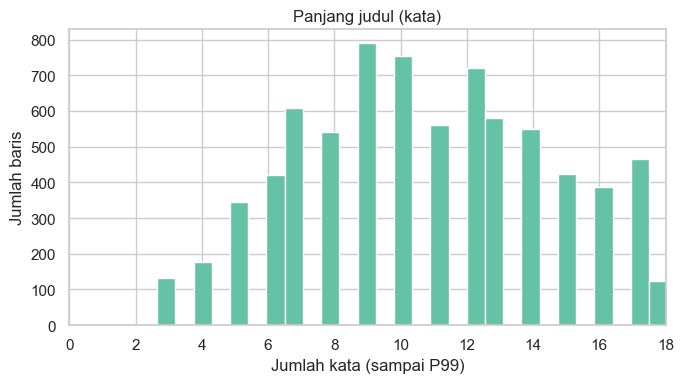

In [15]:
values = df["yt_title_words"]
plt.figure(figsize=(7, 4))
plt.hist(values, bins=40, color=sns.color_palette("Set2")[0])
plt.xlim(0, values.quantile(.99))
plt.title("Panjang judul (kata)")
plt.xlabel("Jumlah kata (sampai P99)")
plt.ylabel("Jumlah baris")
plt.tight_layout()

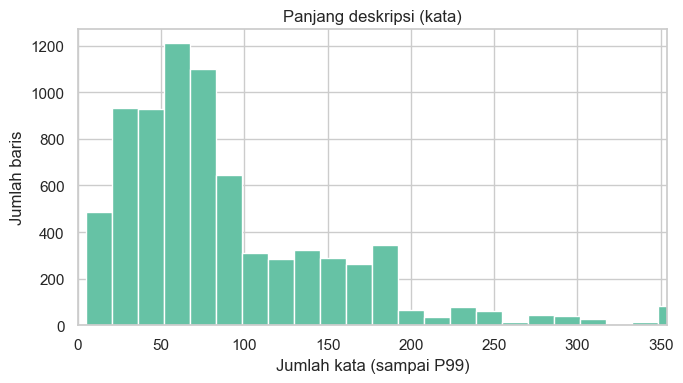

In [16]:
values = df["yt_description_words"]
plt.figure(figsize=(7, 4))
plt.hist(values, bins=40, color=sns.color_palette("Set2")[0])
plt.xlim(0, values.quantile(.99))
plt.title("Panjang deskripsi (kata)")
plt.xlabel("Jumlah kata (sampai P99)")
plt.ylabel("Jumlah baris")
plt.tight_layout()

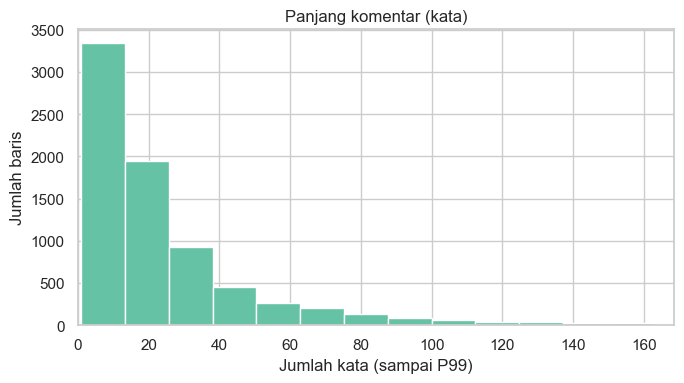

In [17]:
values = df["yt_comment_words"]
plt.figure(figsize=(7, 4))
plt.hist(values, bins=40, color=sns.color_palette("Set2")[0])
plt.xlim(0, values.quantile(.99))
plt.title("Panjang komentar (kata)")
plt.xlabel("Jumlah kata (sampai P99)")
plt.ylabel("Jumlah baris")
plt.tight_layout()

## 7. Pemotongan komentar berdasarkan tokenizer


In [ ]:
MAX_LENGTH = 384
tokenizer_models = [
    ("XLM-RoBERTa-base", "FacebookAI/xlm-roberta-base"),
    ("mBERT uncased", "google-bert/bert-base-multilingual-uncased"),
    ("Twitter-XLM-RoBERTa", "cardiffnlp/twitter-xlm-roberta-base"),
]

emoji_placeholder_pattern = emoji.get_emoji_regexp()
comments = (
    df["yt_comment"].fillna("").astype(str)
    .map(lambda text: emoji_placeholder_pattern.sub(" [EMOJI] ", text).casefold())
    .tolist()
)

truncation_summary = []
truncation_by_language = []

for model_label, model_name in tokenizer_models:
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    token_lengths = []
    for start in tqdm(range(0, len(comments), 128), desc=model_label):
        batch = tokenizer(
            comments[start:start + 128],
            add_special_tokens=True,
            truncation=False,
            verbose=False,
        )
        token_lengths.extend(len(input_ids) for input_ids in batch["input_ids"])

    token_lengths = pd.Series(token_lengths, index=df.index)
    truncated = token_lengths > MAX_LENGTH
    truncation_summary.append({
        "model": model_label,
        "max_length": MAX_LENGTH,
        "jumlah_komentar": len(token_lengths),
        "komentar_terpotong": int(truncated.sum()),
        "persentase_terpotong": round(truncated.mean() * 100, 2),
        "token_p50": int(token_lengths.quantile(0.50)),
        "token_p90": int(token_lengths.quantile(0.90)),
        "token_p95": int(token_lengths.quantile(0.95)),
        "token_p99": int(token_lengths.quantile(0.99)),
        "token_maksimum": int(token_lengths.max()),
    })

    for language, language_indices in df.groupby("language").groups.items():
        language_lengths = token_lengths.loc[language_indices]
        language_truncated = language_lengths > MAX_LENGTH
        truncation_by_language.append({
            "model": model_label,
            "language": language,
            "jumlah_komentar": len(language_lengths),
            "komentar_terpotong": int(language_truncated.sum()),
            "persentase_terpotong": round(language_truncated.mean() * 100, 2),
        })

    del tokenizer

truncation_summary = pd.DataFrame(truncation_summary)
truncation_by_language = pd.DataFrame(truncation_by_language)
display(truncation_summary)
display(truncation_by_language)

truncation_summary.plot(
    kind="bar", x="model", y="persentase_terpotong",
    figsize=(8, 4), legend=False, color=sns.color_palette("Set2", 3)
)
plt.title(f"Persentase komentar terpotong (max_length={MAX_LENGTH})")
plt.xlabel("Model")
plt.ylabel("Komentar terpotong (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

truncation_by_language.pivot(
    index="language", columns="model", values="persentase_terpotong"
).plot(kind="bar", figsize=(8, 4), color=sns.color_palette("Set2", 3))
plt.title(f"Persentase komentar terpotong per bahasa (max_length={MAX_LENGTH})")
plt.xlabel("Bahasa")
plt.ylabel("Komentar terpotong (%)")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## 8. Panjang teks menurut bahasa dan label

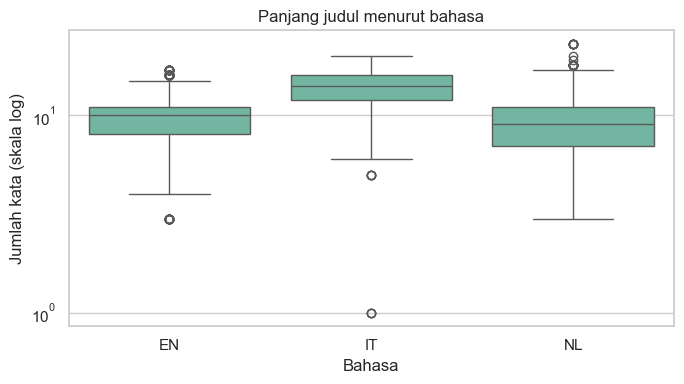

In [18]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="language", y="yt_title_words", color=sns.color_palette("Set2")[0])
plt.yscale("log")
plt.title("Panjang judul menurut bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Jumlah kata (skala log)")
plt.tight_layout()

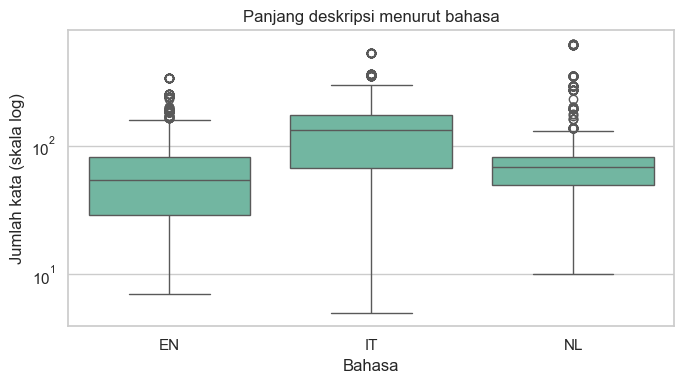

In [19]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="language", y="yt_description_words", color=sns.color_palette("Set2")[0])
plt.yscale("log")
plt.title("Panjang deskripsi menurut bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Jumlah kata (skala log)")
plt.tight_layout()

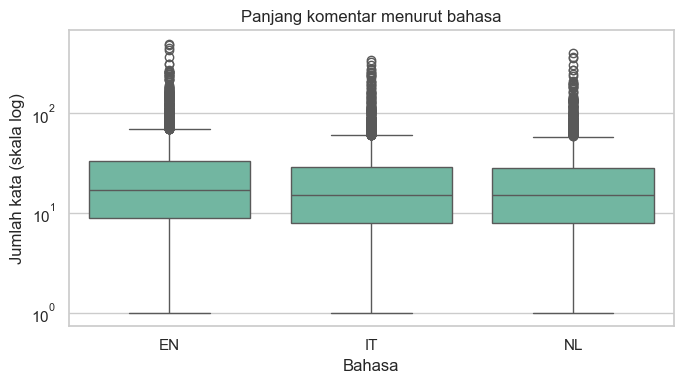

In [20]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="language", y="yt_comment_words", color=sns.color_palette("Set2")[0])
plt.yscale("log")
plt.title("Panjang komentar menurut bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Jumlah kata (skala log)")
plt.tight_layout()

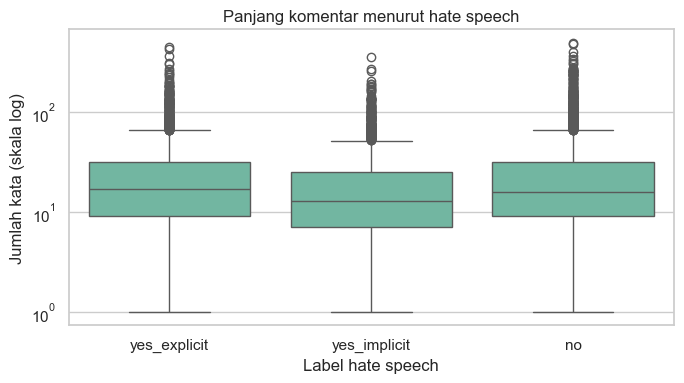

In [21]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="hate_speech", y="yt_comment_words", color=sns.color_palette("Set2")[0])
plt.yscale("log")
plt.title("Panjang komentar menurut hate speech")
plt.xlabel("Label hate speech")
plt.ylabel("Jumlah kata (skala log)")
plt.tight_layout()

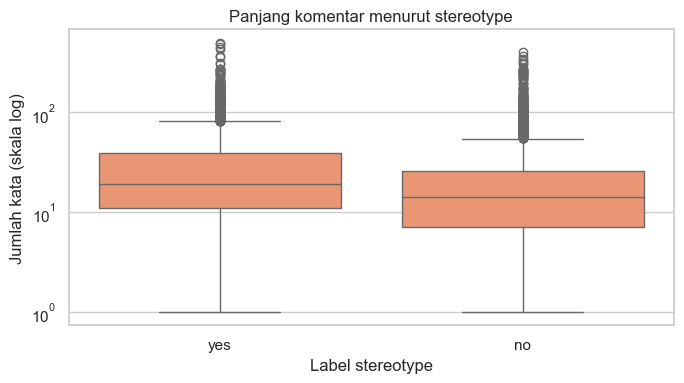

In [22]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="stereotype", y="yt_comment_words", color=sns.color_palette("Set2")[1])
plt.yscale("log")
plt.title("Panjang komentar menurut stereotype")
plt.xlabel("Label stereotype")
plt.ylabel("Jumlah kata (skala log)")
plt.tight_layout()

## 9. Emoji, karakter spesial, mention, dan hashtag

In [23]:
import re

text_cols = ["yt_title", "yt_description", "yt_comment"]
text_names = {"yt_title": "Judul", "yt_description": "Deskripsi", "yt_comment": "Komentar"}
emoji_pattern = r"[\U0001F000-\U0001FAFF\u2600-\u27BF]"
mention_pattern = r"(?<![\w])@[\w.]+"
hashtag_pattern = r"(?<![\w])#[\w]+"

feature_rows = []
for col in text_cols:
    text = df[col].fillna("").astype(str)
    emoji_matches = text.str.findall(emoji_pattern)
    mention_matches = text.str.findall(mention_pattern)
    hashtag_matches = text.str.findall(hashtag_pattern)
    special_matches = (
        text.str.replace(emoji_pattern, "", regex=True)
            .str.replace(mention_pattern, "", regex=True)
            .str.replace(hashtag_pattern, "", regex=True)
            .str.findall(r"[^\w\s]")
    )
    df[f"{col}_emoji_count"] = emoji_matches.str.len()
    df[f"{col}_mention_count"] = mention_matches.str.len()
    df[f"{col}_hashtag_count"] = hashtag_matches.str.len()
    df[f"{col}_special_count"] = special_matches.str.len()
    for feature, matches in [("Emoji", emoji_matches), ("Mention", mention_matches),
                              ("Hashtag", hashtag_matches), ("Karakter spesial", special_matches)]:
        feature_rows.append({
            "kolom": text_names[col], "fitur": feature,
            "baris_dengan_fitur": int(matches.str.len().gt(0).sum()),
            "persentase_baris": round(matches.str.len().gt(0).mean() * 100, 2),
            "jumlah_kemunculan": int(matches.str.len().sum()),
        })

feature_summary = pd.DataFrame(feature_rows)
display(feature_summary.pivot(index="fitur", columns="kolom", values="persentase_baris"))
display(feature_summary)


kolom,Deskripsi,Judul,Komentar
fitur,,,
Emoji,15.39,0.00,15.52
Hashtag,28.39,1.32,0.18
Karakter spesial,99.74,79.52,79.24
Mention,0.00,0.00,0.01


,kolom,fitur,baris_dengan_fitur,persentase_baris,jumlah_kemunculan
0,Judul,Emoji,0,0.00,0
1,Judul,Mention,0,0.00,0
2,Judul,Hashtag,101,1.32,149
3,Judul,Karakter spesial,6065,79.52,20213
4,Deskripsi,Emoji,1174,15.39,4029
5,Deskripsi,Mention,0,0.00,0
6,Deskripsi,Hashtag,2165,28.39,5397
7,Deskripsi,Karakter spesial,7607,99.74,220985
8,Komentar,Emoji,1184,15.52,3466
9,Komentar,Mention,1,0.01,1


In [24]:
comment_feature_summary = []
for language, part in df.groupby("language"):
    for feature, label in [("emoji", "Emoji"), ("mention", "Mention"),
                           ("hashtag", "Hashtag"), ("special", "Karakter spesial")]:
        count_col = f"yt_comment_{feature}_count"
        comment_feature_summary.append({
            "language": language, "fitur": label,
            "baris_dengan_fitur": int(part[count_col].gt(0).sum()),
            "persentase_baris": round(part[count_col].gt(0).mean() * 100, 2),
            "jumlah_kemunculan": int(part[count_col].sum()),
        })
display(pd.DataFrame(comment_feature_summary))


,language,fitur,baris_dengan_fitur,persentase_baris,jumlah_kemunculan
0,EN,Emoji,359,12.01,1050
1,EN,Mention,0,0.00,0
2,EN,Hashtag,9,0.30,10
3,EN,Karakter spesial,2569,85.95,15504
4,IT,Emoji,453,18.88,1481
5,IT,Mention,0,0.00,0
6,IT,Hashtag,2,0.08,3
7,IT,Karakter spesial,1894,78.92,11299
8,NL,Emoji,372,16.62,935
9,NL,Mention,1,0.04,1


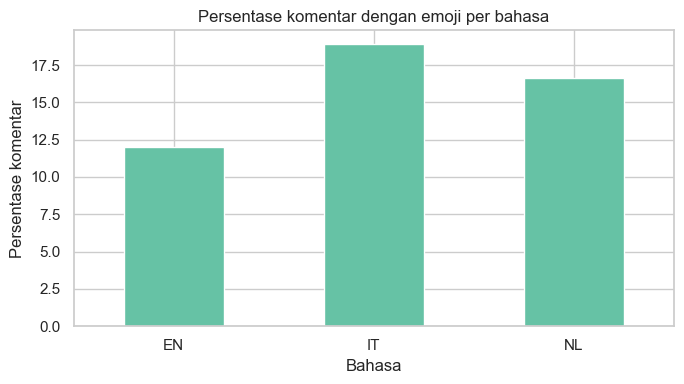

In [25]:
feature_col = "yt_comment_emoji_count"
feature_by_language = (df.assign(ada_fitur=df[feature_col].gt(0))
                       .groupby("language")["ada_fitur"].mean().mul(100).sort_index())
feature_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2")[0])
plt.title("Persentase komentar dengan emoji per bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Persentase komentar")
plt.xticks(rotation=0)
plt.tight_layout()


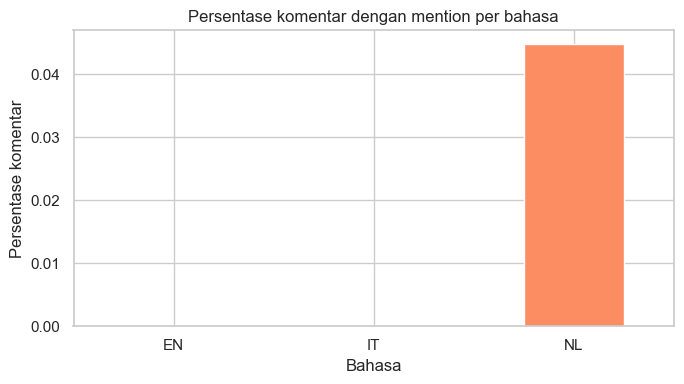

In [26]:
feature_col = "yt_comment_mention_count"
feature_by_language = (df.assign(ada_fitur=df[feature_col].gt(0))
                       .groupby("language")["ada_fitur"].mean().mul(100).sort_index())
feature_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2")[1])
plt.title("Persentase komentar dengan mention per bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Persentase komentar")
plt.xticks(rotation=0)
plt.tight_layout()


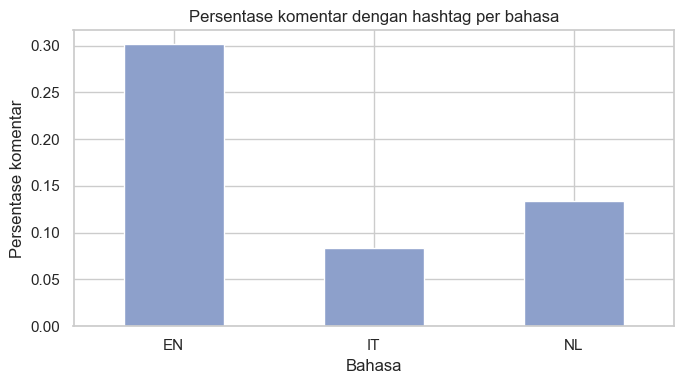

In [27]:
feature_col = "yt_comment_hashtag_count"
feature_by_language = (df.assign(ada_fitur=df[feature_col].gt(0))
                       .groupby("language")["ada_fitur"].mean().mul(100).sort_index())
feature_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2")[2])
plt.title("Persentase komentar dengan hashtag per bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Persentase komentar")
plt.xticks(rotation=0)
plt.tight_layout()


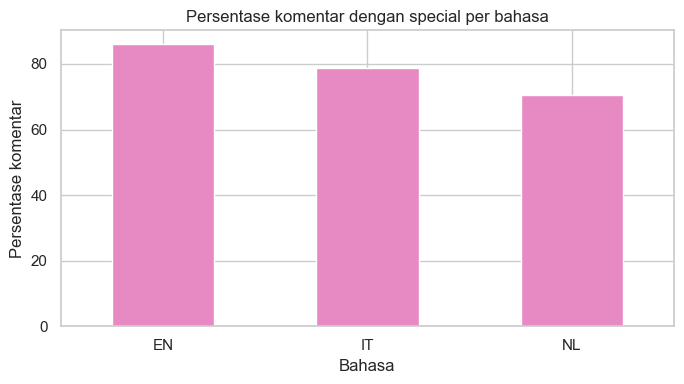

In [28]:
feature_col = "yt_comment_special_count"
feature_by_language = (df.assign(ada_fitur=df[feature_col].gt(0))
                       .groupby("language")["ada_fitur"].mean().mul(100).sort_index())
feature_by_language.plot(kind="bar", figsize=(7, 4), color=sns.color_palette("Set2")[3])
plt.title("Persentase komentar dengan special per bahasa")
plt.xlabel("Bahasa")
plt.ylabel("Persentase komentar")
plt.xticks(rotation=0)
plt.tight_layout()


In [29]:
for feature, pattern in [("Emoji", emoji_pattern), ("Mention", mention_pattern),
                        ("Hashtag", hashtag_pattern)]:
    print(feature)
    display(df.loc[df["yt_comment"].fillna("").astype(str).str.contains(pattern, regex=True),
                   ["language", "yt_comment"]].head(10))

print("Contoh komentar dengan karakter spesial (di luar emoji, mention, hashtag):")
display(df.loc[df["yt_comment_special_count"].gt(0), ["language", "yt_comment"]].head(10))


Emoji


,language,yt_comment
26,EN,A man who thinks he’s a woman who thinks he’s ...
35,EN,"Wow, reality sucks for the delulu huh 😂 but fo..."
45,EN,You Are ALL….. Beautiful HUMAN BEINGS❣️ And de...
58,EN,Another “super spreader” event..😔
71,EN,TRANSGENDERS ARE PEOPLE LIKE YOU AND ME .THEY ...
76,EN,“Pride” is simply a weapon for companies to ap...
78,EN,Mabe they shouldn't comit crimes???!!!😅😅😅😅
88,EN,Support gay 🏳️‍🌈🏳️‍🌈🏳️‍🌈🏳️‍🌈🏳️‍🌈rights in all...
103,EN,"As a bi person, I agree 100% with everything s..."
107,EN,A lot of LGBT people here 😂


Mention


,language,yt_comment
7528,NL,"Lieve allen, er is een LGBTQ+ parade in Noord ..."


Hashtag


,language,yt_comment
837,EN,Wow! Very inspiring and moving. This is so t...
1667,EN,Love wins. #RIP ORLANDO. \nRAINBOW TRIBUTE T...
1679,EN,Proud day to be in American. I cried when I h...
1816,EN,"I'm now HIV negative, Dr Abiola cured me from ..."
2555,EN,I'm imagining that Fred Phelps Sr. is screamin...
2784,EN,So this why they say #Loveislove. Gay marriage...
2847,EN,As Ireland becomes the first country in the wo...
2916,EN,#perfection
2940,EN,"I grew up in this world. Not the Isle of Man, ..."
4744,IT,Che tristezza tutti questi commenti omofobi.\n...


Contoh komentar dengan karakter spesial (di luar emoji, mention, hashtag):


,language,yt_comment
0,EN,She's living in unrepentant defiance to God's ...
1,EN,Rep Mace: Keep on being dedicated to truth and...
2,EN,"We all need Jesus, He said no homosexual shall..."
3,EN,So can two black men adopt a little white girl...
5,EN,"For God, so loved the world that he gave his o..."
6,EN,"Wow, can't believe that anything anti gays wou..."
8,EN,Should’ve kept fighting those desires. Just li...
9,EN,"straight men fetish me,straight women make me ..."
10,EN,"He, if He wins.\nHe's just like every other po..."
11,EN,Christians have been commanded to love one ano...


## 10. Contoh teks ekstrem dan catatan awal

In [30]:
display(
    df.nlargest(10, "yt_comment_words")[[
        "StereoQueerEval_id", "hate_speech", "stereotype", "target",
        "yt_comment_words", "yt_comment"
    ]].reset_index(drop=True)
)

,StereoQueerEval_id,hate_speech,stereotype,target,yt_comment_words,yt_comment
0,training_EN_2039,no,yes,none,496,The inclusion of male athletes in girls' and w...
1,training_EN_2116,no,yes,none,482,It really is very sad to hear people claiming ...
2,training_EN_0858,yes_explicit,yes,"group_l,g,lgbtqia+",449,"Dear girl, happy fasting and prayer. May faith..."
3,training_EN_2706,yes_explicit,yes,group_lgbtqia+,432,"Divide and Conquer, a classic British strategy..."
4,training_NL_0596,no,no,none,404,Ik had dit filmpje gezien gisteravond. En maak...
5,training_EN_0991,yes_explicit,yes,"group_l,g,b,lgbtqia+",366,"satan, also called the adversary or the devil,..."
6,training_NL_1628,no,no,none,366,Je bent perfect Ik vind het echt heel goed dat...
7,training_NL_1667,yes_implicit,yes,group_lgbtqia+,359,Jammer dat ze niet goed kunnen uitleggen wat z...
8,training_IT_2204,no,no,none,340,E' stata assunta contro il parere (magari prof...
9,training_IT_1063,no,no,none,323,a me è successo 6 anni fa sono transessuale av...
